### **Imports**

In [ ]:
%load_ext autoreload
%autoreload 2
%cd ..

import warnings
warnings.filterwarnings("ignore")

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from src.config import (
    SOURCE_ROOT, RENAMED_DIR, EXTRACTED_DATA_DIR, SPLIT_OUTPUT_DIR, 
    SPLITS, VIDEO_EXTENSIONS
)
from src.processing.statistics import (
    analyze_video_formats, get_dataset_durations_metadata, get_splits_metadata_df,
    gather_dataset_geometry, gather_spatial_coordinates, gather_dataset_frame_metadata_df,
    gather_all_splits_geometry, calculate_dataset_local_contrast
)
from src.processing.dataset import verify_filename_syntax, extract_metadata_from_filename
from src.utils.visualization import (
    plot_duration_histogram, plot_dataset_distribution_summary, plot_stacked_splits_distribution,
    plot_grouped_splits_report, plot_dataset_geometry_analysis, plot_spatial_heatmap,
    plot_frame_level_dashboard, plot_local_contrast_analysis
)

### **Video Formats Distribution**

In [2]:
extension_counter, total_folders, total_files = analyze_video_formats(SOURCE_ROOT)

print("-" * 40)
print("STATISTICS RESULTS:")
print("-" * 40)
print(f"Total folders checked: {total_folders}")
print(f"Total files found: {total_files}\n")
print("Format distribution:")

if not extension_counter:
    print("The folder is empty.")
else:
    for ext, count in extension_counter.most_common():
        print(f"  {ext}: {count} items")


----------------------------------------
STATISTICS RESULTS:
----------------------------------------
Total folders checked: 118
Total files found: 610

Format distribution:
  .mp4: 550 items
  .mov: 32 items
  .m4v: 28 items


### **Video Duration Distribution & Interactive Histogram**

In [3]:
durations_data = get_dataset_durations_metadata(RENAMED_DIR, VIDEO_EXTENSIONS)
durations = [d['duration_sec'] for d in durations_data]

print(f"Files found for analysis: {len(durations_data)}")

if durations:
    print("\n📊 DETAILED DISTRIBUTION (Console):")
    counts, bin_edges = np.histogram(durations, bins=50)
    for i in range(len(counts)):
        if counts[i] > 0:
            print(f"From {bin_edges[i]:.1f} to {bin_edges[i+1]:.1f} sec: {counts[i]} videos")
            
    total_duration_sec = sum(durations)
    avg_duration = total_duration_sec / len(durations)
    hours = int(total_duration_sec // 3600)
    minutes = int((total_duration_sec % 3600) // 60)
    
    print(f"\n📊 DATASET STATISTICS:")
    print(f"Successfully read: {len(durations_data)} videos")
    print(f"Total duration: {hours} hours {minutes} minutes ({total_duration_sec:.1f} sec)")
    print(f"Average video duration: {avg_duration:.1f} sec")
    
    print("\n📈 Generating interactive histogram...")
    df_durations = pd.DataFrame(durations_data)
    plot_duration_histogram(df_durations)
else:
    print("No valid videos found.")

Files found for analysis: 594

📊 DETAILED DISTRIBUTION (Console):
From 0.2 to 0.6 sec: 2 videos
From 0.6 to 1.1 sec: 28 videos
From 1.1 to 1.5 sec: 67 videos
From 1.5 to 1.9 sec: 70 videos
From 1.9 to 2.4 sec: 70 videos
From 2.4 to 2.8 sec: 72 videos
From 2.8 to 3.3 sec: 42 videos
From 3.3 to 3.7 sec: 34 videos
From 3.7 to 4.1 sec: 34 videos
From 4.1 to 4.6 sec: 17 videos
From 4.6 to 5.0 sec: 9 videos
From 5.0 to 5.4 sec: 19 videos
From 5.4 to 5.9 sec: 16 videos
From 5.9 to 6.3 sec: 16 videos
From 6.3 to 6.7 sec: 13 videos
From 6.7 to 7.2 sec: 15 videos
From 7.2 to 7.6 sec: 7 videos
From 7.6 to 8.1 sec: 10 videos
From 8.1 to 8.5 sec: 5 videos
From 8.5 to 8.9 sec: 5 videos
From 8.9 to 9.4 sec: 4 videos
From 9.4 to 9.8 sec: 2 videos
From 9.8 to 10.2 sec: 5 videos
From 10.2 to 10.7 sec: 3 videos
From 10.7 to 11.1 sec: 2 videos
From 11.1 to 11.5 sec: 4 videos
From 11.5 to 12.0 sec: 3 videos
From 12.0 to 12.4 sec: 2 videos
From 12.4 to 12.9 sec: 1 videos
From 12.9 to 13.3 sec: 1 videos
From

### **TOP-5 Longest Videos**

In [4]:
longest_videos = sorted(durations_data, key=lambda x: x['duration_sec'], reverse=True)

print("🛑 TOP-5 Longest Videos in Dataset:")
for i, v in enumerate(longest_videos[:5]):
    print(f"{i+1}. {v['filename']} — {v['duration_sec']:.1f} sec")

🛑 TOP-5 Longest Videos in Dataset:
1. wing_rgb_sky_428.mp4 — 22.0 sec
2. delta_rgb_field_068.mp4 — 21.1 sec
3. delta_rgb_field_069.mp4 — 20.1 sec
4. wing_rgb_field_284.mp4 — 18.4 sec
5. wing_rgb_field_280.mp4 — 18.4 sec


### **Raw Episodes Folder Duration Audit**

In [5]:
raw_durations_data = get_dataset_durations_metadata(SOURCE_ROOT, VIDEO_EXTENSIONS)
raw_durations = [d['duration_sec'] for d in raw_durations_data]

print(f"Videos found for raw episodes analysis: {len(raw_durations_data)}")

if raw_durations:
    total_raw_sec = sum(raw_durations)
    avg_raw_duration = total_raw_sec / len(raw_durations)
    hours = int(total_raw_sec // 3600)
    minutes = int((total_raw_sec % 3600) // 60)
    
    print(f"\n📊 RAW EPISODES STATISTICS:")
    print(f"Successfully processed: {len(raw_durations_data)} videos")
    print(f"Total raw duration: {hours} hours {minutes} minutes ({total_raw_sec:.1f} sec)")
    print(f"Average raw video duration: {avg_raw_duration:.1f} sec")
else:
    print("No valid videos found in raw episodes folder.")

Videos found for raw episodes analysis: 610

📊 RAW EPISODES STATISTICS:
Successfully processed: 610 videos
Total raw duration: 0 hours 40 minutes (2403.9 sec)
Average raw video duration: 3.9 sec


### **Spelling & Typo Check**

In [6]:
VALID_TARGETS = ["delta", "cross", "wing", "no_drone"]
VALID_CAMERAS = ["rgb", "thermal"]
VALID_BGS = ["sky", "uniform", "field", "forest", "urban", "horizon", "complex"]

errors = []
valid_count = 0

print("Starting dataset filename spelling check...\n" + "="*50)

for video_path in RENAMED_DIR.iterdir():
    if video_path.suffix.lower() not in VIDEO_EXTENSIONS:
        continue

    error_reason = verify_filename_syntax(
        filename=video_path.name,
        valid_targets=VALID_TARGETS,
        valid_cameras=VALID_CAMERAS,
        valid_bgs=VALID_BGS
    )

    if error_reason:
        errors.append((video_path.name, error_reason))
    else:
        valid_count += 1

if errors:
    print(f"🚨 FOUND SPELLING ERRORS/TYPOS: {len(errors)}")
    print("-" * 50)
    for bad_file, reason in errors:
        print(f"[!] {reason} -> {bad_file}")
else:
    print(f"✅ All {valid_count} files are named correctly.")
print("="*50)

Starting dataset filename spelling check...
✅ All 594 files are named correctly.


### **Dataset Distribution Summary**

📊 BASE DATASET METADATA STATISTICS
Total videos in dataset: 594
--------------------------------------------------
Distribution by drone SHAPE:
Shape
wing     358
delta    196
cross     40
--------------------------------------------------
Distribution by CAMERA type:
Camera
rgb        316
thermal    278
--------------------------------------------------
Distribution by BACKGROUND:
Background
sky        283
field      169
horizon    117
complex     25


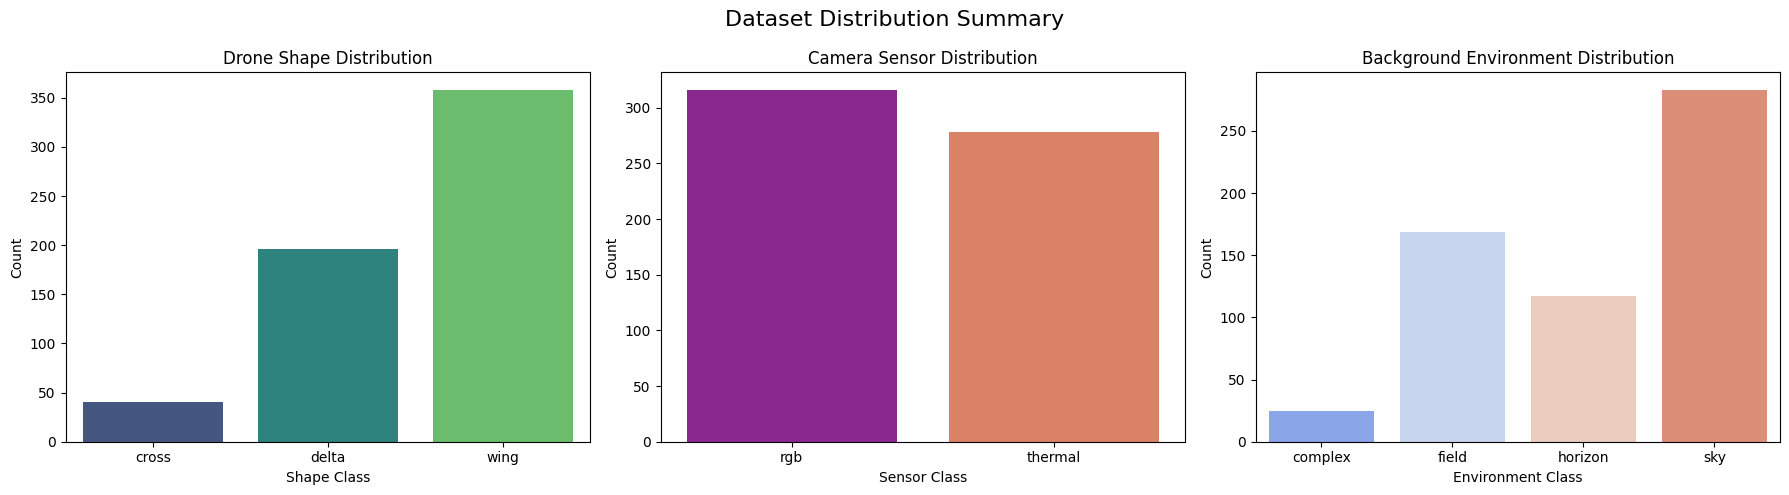

In [7]:
data_meta = []

for video_path in RENAMED_DIR.iterdir():
    if video_path.suffix.lower() in VIDEO_EXTENSIONS:
        meta = extract_metadata_from_filename(video_path.name)
        if meta:
            shape, camera, bg = meta
            combined_class = f"{shape}_{camera}_{bg}"
            data_meta.append({
                'File': video_path.name,
                'Shape': shape,
                'Camera': camera,
                'Background': bg,
                'Combined Class': combined_class
            })

df_meta = pd.DataFrame(data_meta)

print("📊 BASE DATASET METADATA STATISTICS")
print("="*50)
print(f"Total videos in dataset: {len(df_meta)}")
print("-" * 50)
print("Distribution by drone SHAPE:")
print(df_meta['Shape'].value_counts().to_string())
print("-" * 50)
print("Distribution by CAMERA type:")
print(df_meta['Camera'].value_counts().to_string())
print("-" * 50)
print("Distribution by BACKGROUND:")
print(df_meta['Background'].value_counts().to_string())
print("="*50)

plot_dataset_distribution_summary(df_meta)

### **Summary Balance Report**

In [8]:
counts = df_meta['Combined Class'].value_counts()
percentages = df_meta['Combined Class'].value_counts(normalize=True) * 100

distribution_report = pd.DataFrame({
    'Video Count': counts,
    'Percentage (%)': percentages.round(2)
}).reset_index()

distribution_report.columns = ['Combined Class', 'Video Count', 'Percentage (%)']

print("📊 COMBINED CLASSES QUANTITATIVE AND PERCENTAGE DISTRIBUTION")
print("=" * 75)
print(f"Total number of videos in dataset: {len(df_meta)}")
print("=" * 75)
print(distribution_report.to_string(index=False))
print("=" * 75)

📊 COMBINED CLASSES QUANTITATIVE AND PERCENTAGE DISTRIBUTION
Total number of videos in dataset: 594
       Combined Class  Video Count  Percentage (%)
         wing_rgb_sky          131           22.05
     wing_thermal_sky           83           13.97
  delta_thermal_field           54            9.09
       wing_rgb_field           51            8.59
delta_thermal_horizon           37            6.23
     wing_rgb_horizon           37            6.23
      delta_rgb_field           34            5.72
 wing_thermal_horizon           28            4.71
    delta_thermal_sky           26            4.38
        delta_rgb_sky           22            3.70
   wing_thermal_field           20            3.37
        cross_rgb_sky           11            1.85
    cross_thermal_sky           10            1.68
    delta_rgb_complex            9            1.52
    delta_rgb_horizon            8            1.35
delta_thermal_complex            6            1.01
      cross_rgb_field            5

### **Single-Scan Stratification Audit**

In [9]:
print("[*] Performing single-scan stratification audit...")

df_splits = get_splits_metadata_df(SPLIT_OUTPUT_DIR, SPLITS)

if df_splits.empty:
    print("[-] Error: No split data found. Verify your SPLIT_OUTPUT_DIR.")
else:
    pivot_counts = pd.crosstab(df_splits['Class'], df_splits['Split'])
    row_totals = pivot_counts.sum(axis=1)
    
    pivot_pct = pivot_counts.div(row_totals, axis=0) * 100
    pivot_pct['Total (Count)'] = row_totals
    pivot_pct = pivot_pct.sort_values(by='Total (Count)', ascending=False)
    
    for col in pivot_counts.columns:
        pivot_pct[col] = pivot_pct[col].apply(lambda x: f"{x:.1f}%")

    print("\n[*] CLASS DISTRIBUTION BY SPLIT (PERCENTAGES):")
    print("=" * 75)
    
    expected_columns = ['TRAIN', 'VAL', 'TEST', 'Total (Count)']
    available_columns = [col for col in expected_columns if col in pivot_pct.columns]
    
    print(pivot_pct[available_columns].to_string())
    print("=" * 75)
    print("\n[i] Expected distribution: ~70.0% / ~15.0% / ~15.0%")

[*] Performing single-scan stratification audit...

[*] CLASS DISTRIBUTION BY SPLIT (PERCENTAGES):
Split                   TRAIN    VAL   TEST  Total (Count)
Class                                                     
wing_rgb_sky            69.5%  15.3%  15.3%            131
wing_thermal_sky        69.9%  14.5%  15.7%             83
delta_thermal_field     68.5%  16.7%  14.8%             54
wing_rgb_field          68.6%  13.7%  17.6%             51
wing_rgb_horizon        73.0%  16.2%  10.8%             37
delta_thermal_horizon   70.3%  13.5%  16.2%             37
delta_rgb_field         70.6%  14.7%  14.7%             34
wing_thermal_horizon    71.4%  17.9%  10.7%             28
delta_thermal_sky       69.2%  15.4%  15.4%             26
delta_rgb_sky           72.7%  13.6%  13.6%             22
wing_thermal_field      75.0%  10.0%  15.0%             20
cross_rgb_sky           81.8%   9.1%   9.1%             11
cross_thermal_sky       70.0%  20.0%  10.0%             10
delta_rgb_comple

### **Stacked Class Distribution Visualisation**

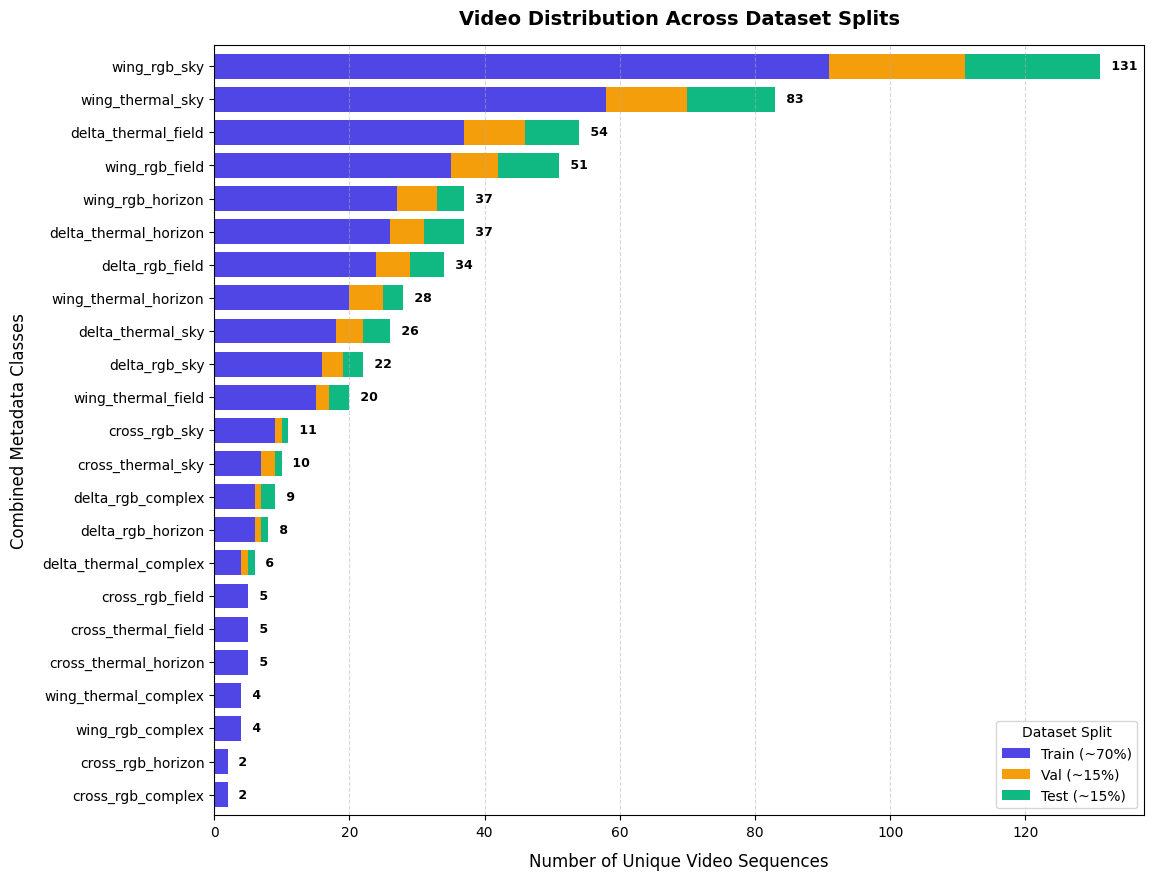

In [ ]:
if df_splits.empty:
    print("[-] Error: No data available for visualization.")
else:
    plot_stacked_splits_distribution(df_splits)

### **Grouped environment, sensor and shape distributions**

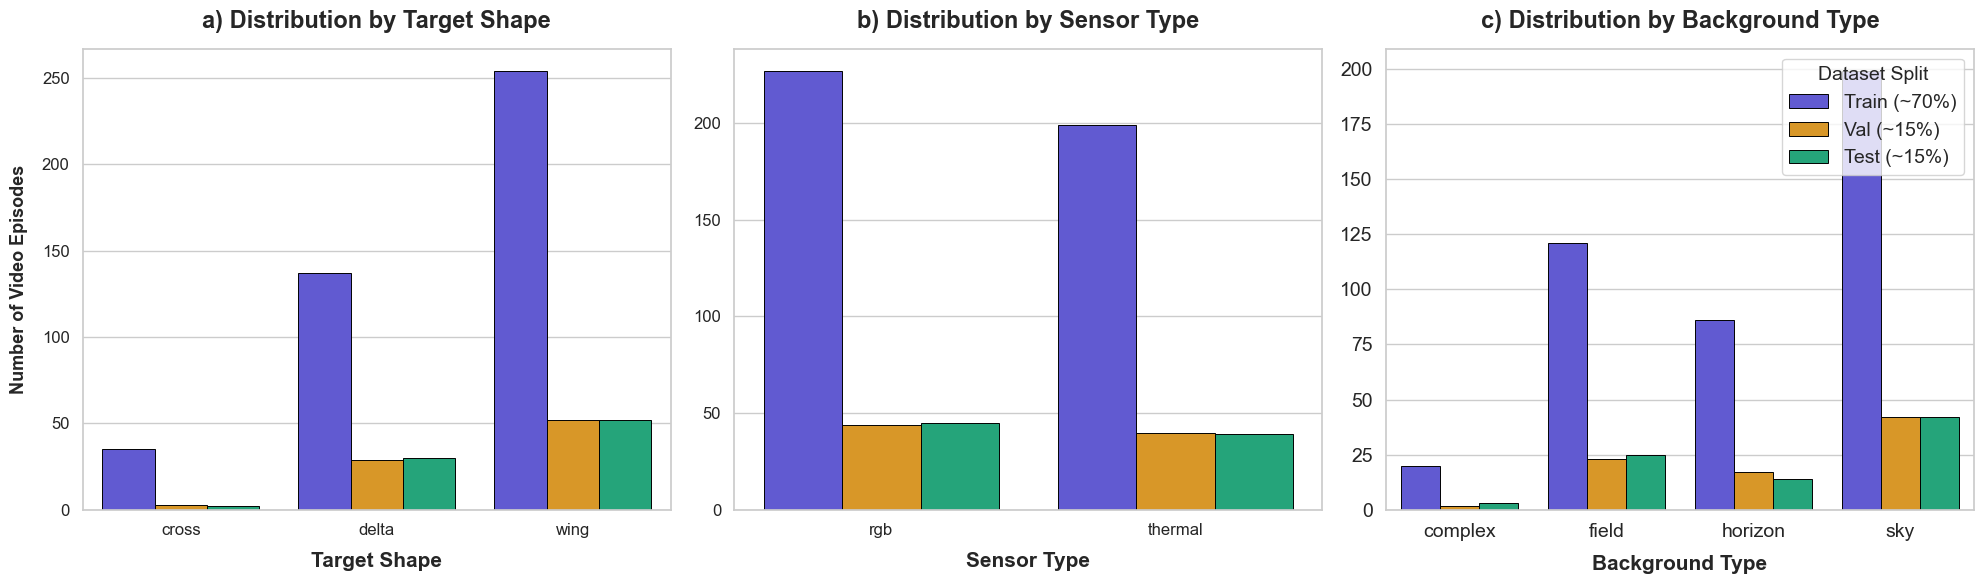

In [ ]:
if df_splits.empty:
    print("[-] Error: No data available for visualization.")
else:
    plot_grouped_splits_report(df_splits)

### **Train BBox scale & Geometry Analysis**

IMAGE DIMENSIONS & SHAPES REPORT
Total Unique Resolutions: 12

Resolution Distribution Count:
width  height
1920   1080      2025
1350   1080      1963
848    544       1737
1280   720       1344
848    464        257
       640        227
       656        221
1920   1072       220
848    496         58
       480         51
1280   1040        40
848    576         34
dtype: int64

Image Aspect Ratio Statistics:
count    8177.000000
mean        1.576310
std         0.224699
min         1.230769
10%         1.250000
25%         1.292683
50%         1.558824
75%         1.777778
90%         1.777778
max         1.827586
Name: aspect_ratio, dtype: float64

TARGET (BBOX) GEOMETRY REPORT
Total Bounding Boxes Analyzed: 8177

Bounding Box Width (pixels):
count    8177.000000
mean      501.263017
std       431.442976
min        17.000550
10%        89.999360
25%       175.999856
50%       363.000150
75%       706.999680
90%      1135.399932
max      1920.000000
Name: pixel_width, dtype: float

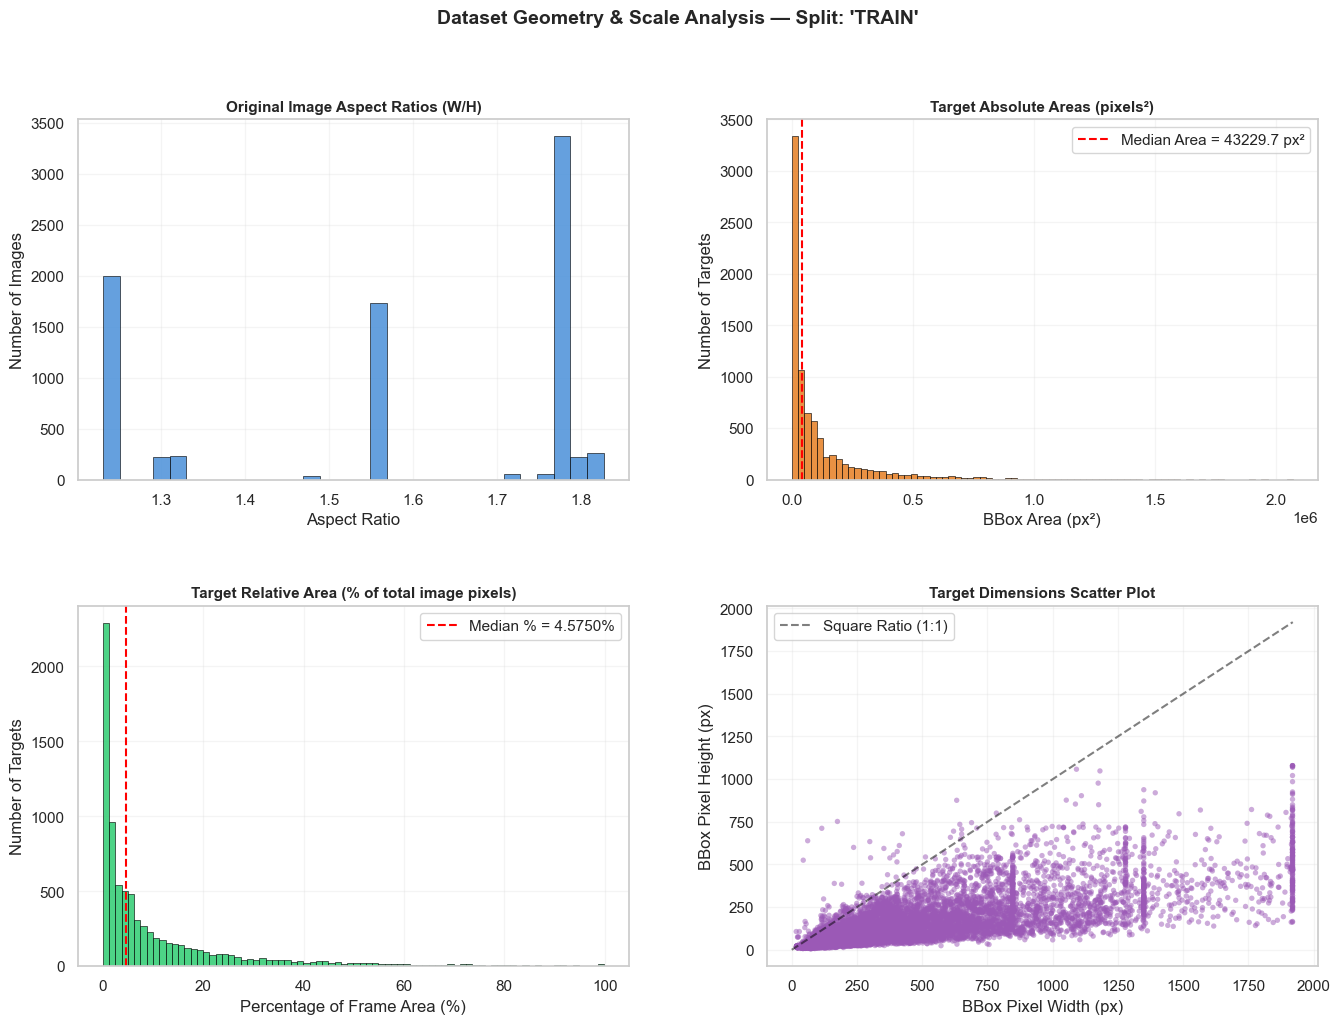

In [12]:
TARGET_SPLIT = "train"
POS_DIR = EXTRACTED_DATA_DIR / TARGET_SPLIT / "RAW_POSITIVES"

df_images, df_bboxes = gather_dataset_geometry(POS_DIR)

print("="*60)
print("IMAGE DIMENSIONS & SHAPES REPORT")
print("="*60)
print(f"Total Unique Resolutions: {df_images.groupby(['width', 'height']).size().count()}")
print("\nResolution Distribution Count:")
print(df_images.groupby(['width', 'height']).size().sort_values(ascending=False))
print("\nImage Aspect Ratio Statistics:")
print(df_images["aspect_ratio"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))

print("\n" + "="*60)
print("TARGET (BBOX) GEOMETRY REPORT")
print("="*60)
print(f"Total Bounding Boxes Analyzed: {len(df_bboxes)}")
print("\nBounding Box Width (pixels):")
print(df_bboxes["pixel_width"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))
print("\nBounding Box Height (pixels):")
print(df_bboxes["pixel_height"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))
print("\nBounding Box Area (pixels²):")
print(df_bboxes["pixel_area"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))
print("\nBounding Box Relative Area (% of total image area):")
print(df_bboxes["relative_area_pct"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95]))

plot_dataset_geometry_analysis(df_images, df_bboxes, TARGET_SPLIT)

### **BBox Spatial Coordinate distribution Hexbin Heatmap**

           SPATIAL COORDINATE METRICS               
Total Bounding Boxes Parsed: 12,000
X Center Mean (Width)      : 0.5091 (Std Dev: 0.1250)
Y Center Mean (Height)     : 0.4298 (Std Dev: 0.2204)


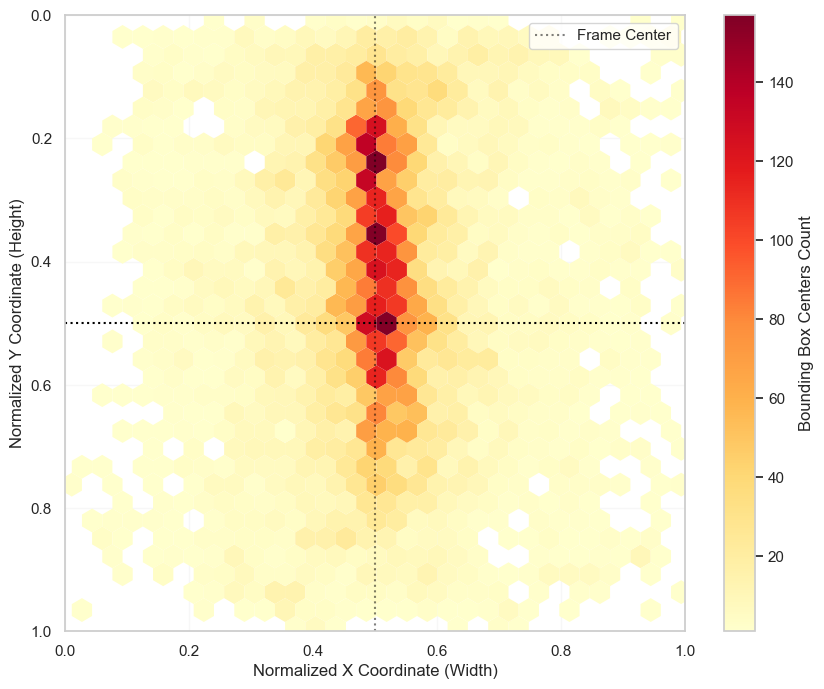

In [13]:
x_centers, y_centers, total_boxes = gather_spatial_coordinates(EXTRACTED_DATA_DIR, SPLITS)

if total_boxes == 0:
    print("[!] Error: No valid bounding boxes parsed.")
else:
    mean_x, std_x = np.mean(x_centers), np.std(x_centers)
    mean_y, std_y = np.mean(y_centers), np.std(y_centers)

    print("="*60)
    print("           SPATIAL COORDINATE METRICS               ")
    print("="*60)
    print(f"Total Bounding Boxes Parsed: {total_boxes:,}")
    print(f"X Center Mean (Width)      : {mean_x:.4f} (Std Dev: {std_x:.4f})")
    print(f"Y Center Mean (Height)     : {mean_y:.4f} (Std Dev: {std_y:.4f})")
    print("="*60)

    plot_spatial_heatmap(x_centers, y_centers)

### **Final Frame-Level Dataset statistical report**

[+] Successfully parsed metadata for 13,200 total frames.

         FINAL DATASET STATISTICAL REPORT (FRAMES)          
Total Extracted Frames  : 13,200
Positive Frames (Drones): 12,000 (90.9%)
Negative Frames (Empty) : 1,200 (9.1%)
------------------------------------------------------------
SPLIT DISTRIBUTION:
  * TRAIN Split: Total = 8987  | Positives = 8177  | Negatives = 810 
  * VAL   Split: Total = 1689  | Positives = 1542  | Negatives = 147 
  * TEST  Split: Total = 2524  | Positives = 2281  | Negatives = 243 


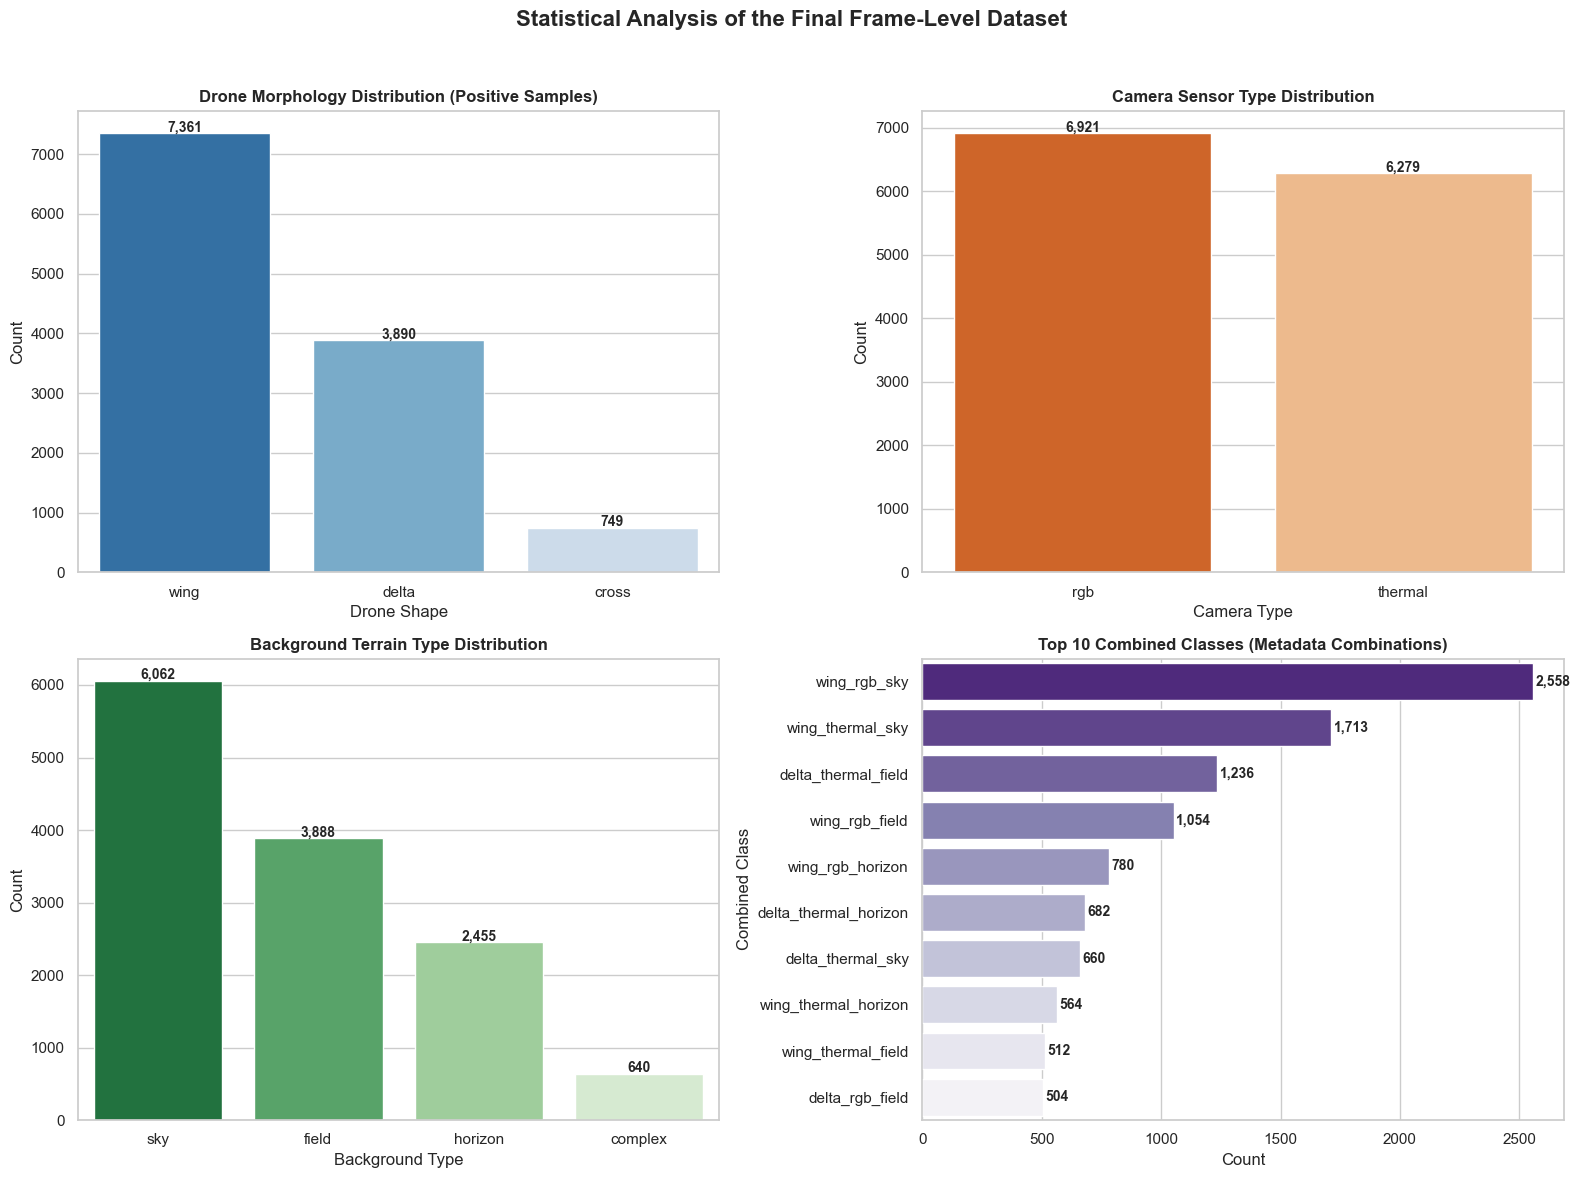

In [16]:
df_frames = gather_dataset_frame_metadata_df(EXTRACTED_DATA_DIR, SPLITS)

if df_frames.empty:
    print(f"[-] Error: No image files found in {EXTRACTED_DATA_DIR}")
else:
    print(f"[+] Successfully parsed metadata for {len(df_frames):,} total frames.")

    total_frames = len(df_frames)
    positives = df_frames[df_frames["is_positive"]]
    negatives = df_frames[~df_frames["is_positive"]]

    print("\n" + "="*60)
    print("         FINAL DATASET STATISTICAL REPORT (FRAMES)          ")
    print("="*60)
    print(f"Total Extracted Frames  : {total_frames:,}")
    print(f"Positive Frames (Drones): {len(positives):,} ({len(positives)/total_frames*100:.1f}%)")
    print(f"Negative Frames (Empty) : {len(negatives):,} ({len(negatives)/total_frames*100:.1f}%)")
    print("-" * 60)
    print("SPLIT DISTRIBUTION:")
    for split in SPLITS:
        split_df = df_frames[df_frames["split"] == split]
        split_pos = split_df[split_df["is_positive"]]
        split_neg = split_df[~split_df["is_positive"]]
        print(f"  * {split.upper():<5} Split: Total = {len(split_df):<5} | Positives = {len(split_pos):<5} | Negatives = {len(split_neg):<4}")
    print("="*60)

    shape_counts = positives[positives["shape"] != "no_drone"]["shape"].value_counts()
    camera_counts = df_frames[~df_frames["camera"].isin(["drone", "unknown"])]["camera"].value_counts()
    bg_counts = df_frames[~df_frames["background"].isin(["rgb", "unknown"])]["background"].value_counts()
    combined_counts = df_frames["combined_class"].value_counts().head(10)

    plot_frame_level_dashboard(df_frames, shape_counts, camera_counts, bg_counts, combined_counts)


### **Target BBox Absolute Area COCO Analysis**

           TARGET SIZE METRICS REPORT               
Total Bounding Boxes Analyzed: 12,000
Mean Width  : 472.81 +/- 413.07 px
Mean Height : 150.09 +/- 144.38 px
Mean Area   : 114258.8 px²
Mean Aspect Ratio (W/H)      : 3.861


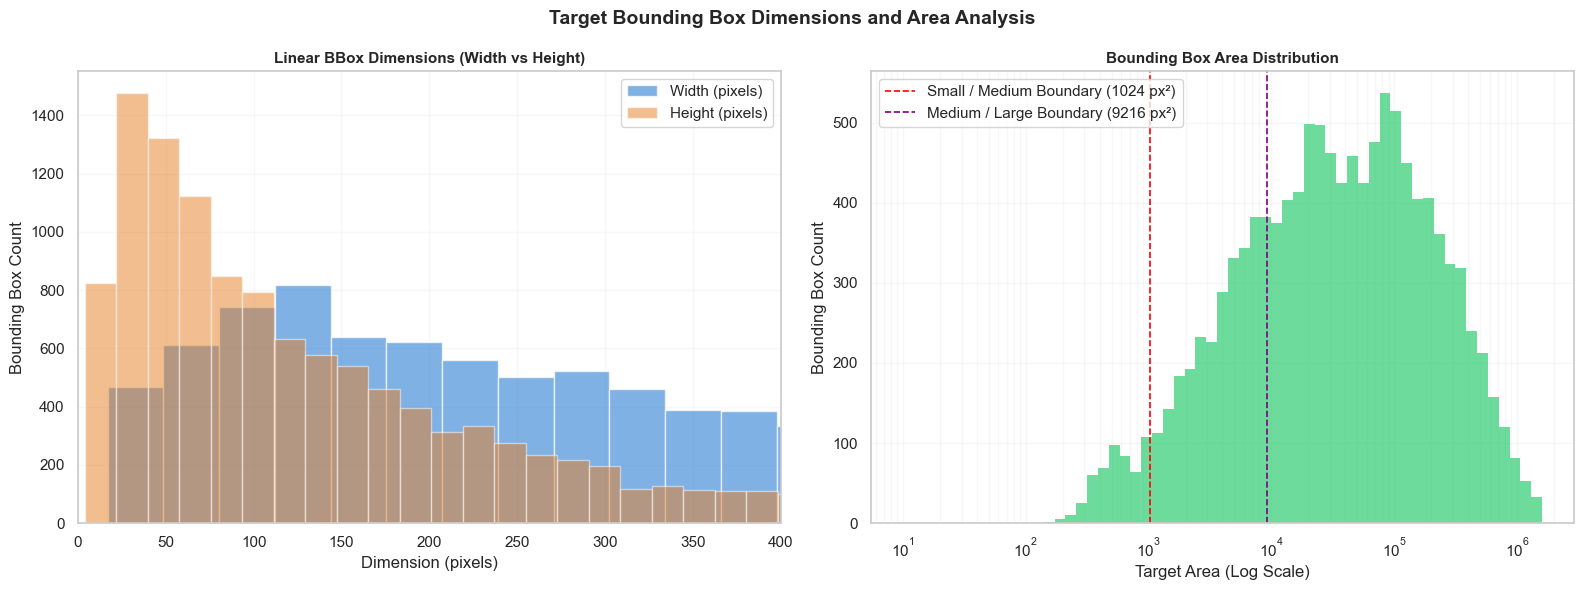

In [20]:
df_all_bboxes = gather_all_splits_geometry(EXTRACTED_DATA_DIR, SPLITS)

if df_all_bboxes.empty:
    print("[!] Error: No bounding boxes parsed.")
else:
    total_boxes = len(df_all_bboxes)
    widths = df_all_bboxes["pixel_width"].to_numpy()
    heights = df_all_bboxes["pixel_height"].to_numpy()
    areas = df_all_bboxes["pixel_area"].to_numpy()
    aspect_ratios = df_all_bboxes["aspect_ratio"].to_numpy()

    print("="*60)
    print("           TARGET SIZE METRICS REPORT               ")
    print("="*60)
    print(f"Total Bounding Boxes Analyzed: {total_boxes:,}")
    print(f"Mean Width  : {np.mean(widths):.2f} +/- {np.std(widths):.2f} px")
    print(f"Mean Height : {np.mean(heights):.2f} +/- {np.std(heights):.2f} px")
    print(f"Mean Area   : {np.mean(areas):.1f} px²")
    print(f"Mean Aspect Ratio (W/H)      : {np.mean(aspect_ratios):.3f}")
    print("="*60)

    # Reusing plot metrics structure
    from src.processing.statistics import gather_all_splits_geometry
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle("Target Bounding Box Dimensions and Area Analysis", fontsize=14, fontweight="bold")

    axes[0].hist(widths, bins=60, color="#4A90D9", alpha=0.7, label="Width (pixels)")
    axes[0].hist(heights, bins=60, color="#E67E22", alpha=0.5, label="Height (pixels)")
    axes[0].set_title("Linear BBox Dimensions (Width vs Height)", fontsize=11, fontweight="bold")
    axes[0].set_xlabel("Dimension (pixels)")
    axes[0].set_ylabel("Bounding Box Count")
    axes[0].set_xlim(0, 400)  
    axes[0].legend()
    axes[0].grid(True, alpha=0.15)

    bins_log = np.logspace(np.log10(10), np.log10(1.6e6), 60)
    axes[1].hist(areas, bins=bins_log, color="#2ECC71", alpha=0.7, edgecolor="none")
    axes[1].set_xscale("log")
    
    axes[1].axvline(1024, color="red", linestyle="--", linewidth=1.2, label="Small / Medium Boundary (1024 px²)")
    axes[1].axvline(9216, color="purple", linestyle="--", linewidth=1.2, label="Medium / Large Boundary (9216 px²)")
    
    axes[1].set_title("Bounding Box Area Distribution", fontsize=11, fontweight="bold")
    axes[1].set_xlabel("Target Area (Log Scale)")
    axes[1].set_ylabel("Bounding Box Count")
    axes[1].legend()
    axes[1].grid(True, which="both", alpha=0.15)
    plt.tight_layout()
    plt.show()

### **Local target-to-background Weber Contrast**

         LOCAL CONTRAST STATISTICAL REPORT          
Camera Sensor: RGB
  Mean Contrast   : 0.2284 +/- 0.2965
  Median Contrast : 0.1628
------------------------------------------------------------
Camera Sensor: THERMAL
  Mean Contrast   : 1.9299 +/- 7.8700
  Median Contrast : 0.2589
------------------------------------------------------------


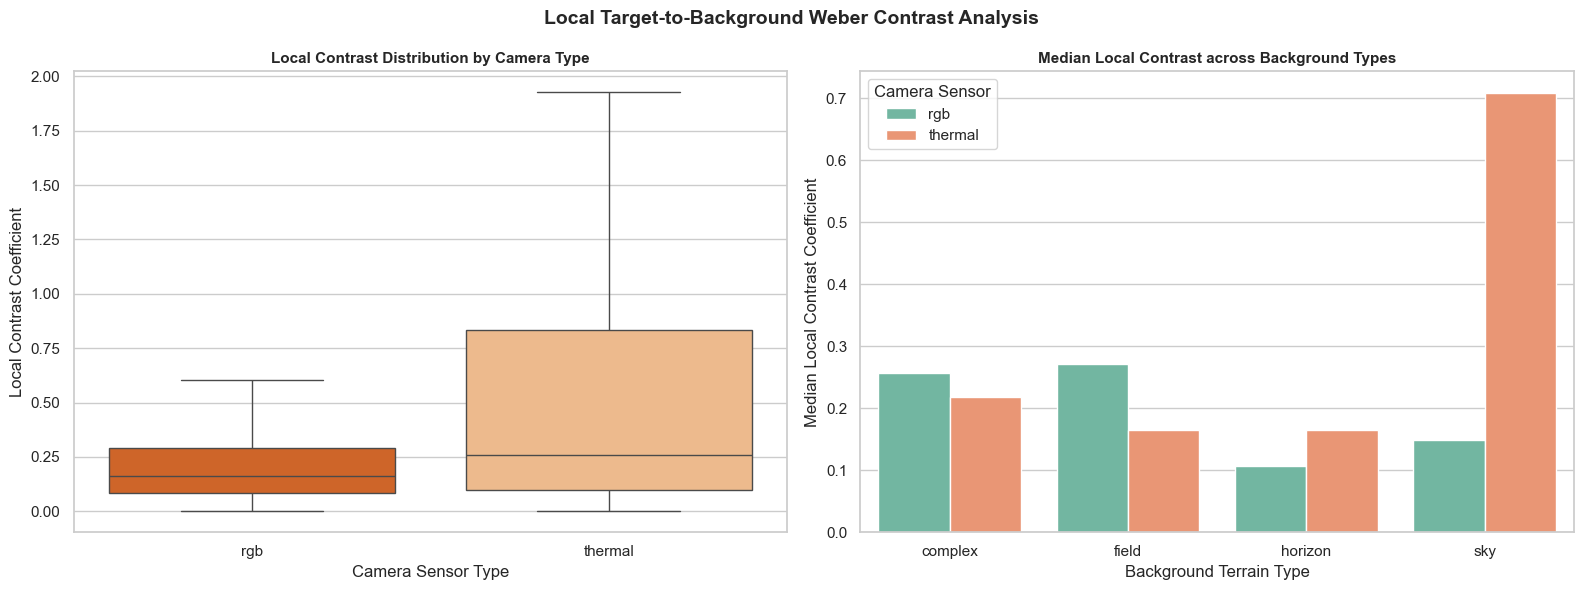

In [21]:
df_contrast = calculate_dataset_local_contrast(EXTRACTED_DATA_DIR, SPLITS)

if df_contrast.empty:
    print("[!] Error: No valid contract metrics computed.")
else:
    print("="*60)
    print("         LOCAL CONTRAST STATISTICAL REPORT          ")
    print("="*60)
    for cam in df_contrast["camera"].unique():
        cam_df = df_contrast[df_contrast["camera"] == cam]
        print(f"Camera Sensor: {cam.upper()}")
        print(f"  Mean Contrast   : {np.mean(cam_df['contrast']):.4f} +/- {np.std(cam_df['contrast']):.4f}")
        print(f"  Median Contrast : {np.median(cam_df['contrast']):.4f}")
        print("-" * 60)
    print("="*60)

    plot_local_contrast_analysis(df_contrast)